In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("quantbruce/real-estate-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\famil\.cache\kagglehub\datasets\quantbruce\real-estate-price-prediction\versions\1


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # Seaborn sirve para crear gráficos estadísticos atractivos y complejos en Python de forma rápida y sencilla
import hvplot.pandas # hvplot es una biblioteca de Python que sirve para crear visualizaciones de datos interactivas y dinámicas de forma rápida y sencilla.

from sklearn.model_selection import train_test_split # Model_selection sirve para organizar, evaluar y optimizar los modelos de aprendizaje automático y train_test_split divide un conjunto de datos en dos grupos: uno para entrenar el modelo de Machine Learning y otro para evaluarlo
from sklearn import metrics
from sklearn.linear_model import LinearRegression


Ahora vamos a observar lo que tiene el dataset para darnos una primera introduccion

In [ ]:
df = pd.read_csv('Real_estate.csv')
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [ ]:
# Dimensiones del dataset
df.shape

(414, 8)

In [ ]:
# Ahora tenemos un resumen conciso y general de la estructura de un DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


A continuacion vamos a ver que es la correlación, que mide que tan relacionadas estan dos variables y en que direccion se mueven juntas. 
Por ejemplo, estamos analizando el precio de una casa y su distancia con otros lugares. Si cuanto mas lejos esta la casa de la estacion, el precio es mas barato entonces la correlacion es negativa. Si cuanto mas cerca esta de comercios mas cara es la casa entonces podemos encontrar una correlacion positiva entre comercios y la casa. Si dos variables no muestran correalcion (La correlacion se da en una relacion lineal) su valor tiende a cero

La correlacion va de -1 a 1 
- -1 Negativa perfecta (Pendiente negativa - Primer ejemplo)
- 0 Sin relacion lineal
- 1 Positiva perfecta (Pendiente positiva - Segundo ejemplo)

Otra cosa para aclarar es que la correlacion no significa causalidad, es decir que dos variables esten relacionadas como comercios y casa no significa que si hay comercios si o si el valor de la casa suba.


| Correlación (valor absoluto) | Interpretación |
| :--- | :--- |
| 0.00 – 0.19 | Muy débil o prácticamente nula |
| 0.20 – 0.39 | Débil |
| 0.40 – 0.59 | Moderada |
| 0.60 – 0.79 | Fuerte |
| 0.80 – 1.00 | Muy fuerte |


In [ ]:
df.corr()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
No,1.000000,-0.048658,-0.032808,-0.013573,-0.012699,-0.010110,-0.011059,-0.028587
X1 transaction date,-0.048658,1.000000,0.017549,0.060880,0.009635,0.035058,-0.041082,0.087491
X2 house age,-0.032808,0.017549,1.000000,0.025622,0.049593,0.054420,-0.048520,-0.210567
X3 distance to the nearest MRT station,-0.013573,0.060880,0.025622,1.000000,-0.602519,-0.591067,-0.806317,-0.673613
X4 number of convenience stores,-0.012699,0.009635,0.049593,-0.602519,1.000000,0.444143,0.449099,0.571005
X5 latitude,-0.010110,0.035058,0.054420,-0.591067,0.444143,1.000000,0.412924,0.546307
X6 longitude,-0.011059,-0.041082,-0.048520,-0.806317,0.449099,0.412924,1.000000,0.523287
Y house price of unit area,-0.028587,0.087491,-0.210567,-0.673613,0.571005,0.546307,0.523287,1.000000


Aca podemos observar que:
- Relaciones fuertes:
    - Precio con la distancia con la estacion
- Relaciones moderadas-fuertes:
    - Precio con tiendas de conveniencia
    - Precio con latitud y longitud (Direccion de la casa)
- Relaciones debiles:
    - Precio con la fecha de compra
    - Precio con años de antiguedad de la casa


Ahora vamos a observar la matriz de correlacion: Es lo mismo que lo anterior pero para verlo mas visualmente, especialmente para mostrarle a una persona que no entiende de numeros

<Axes: >

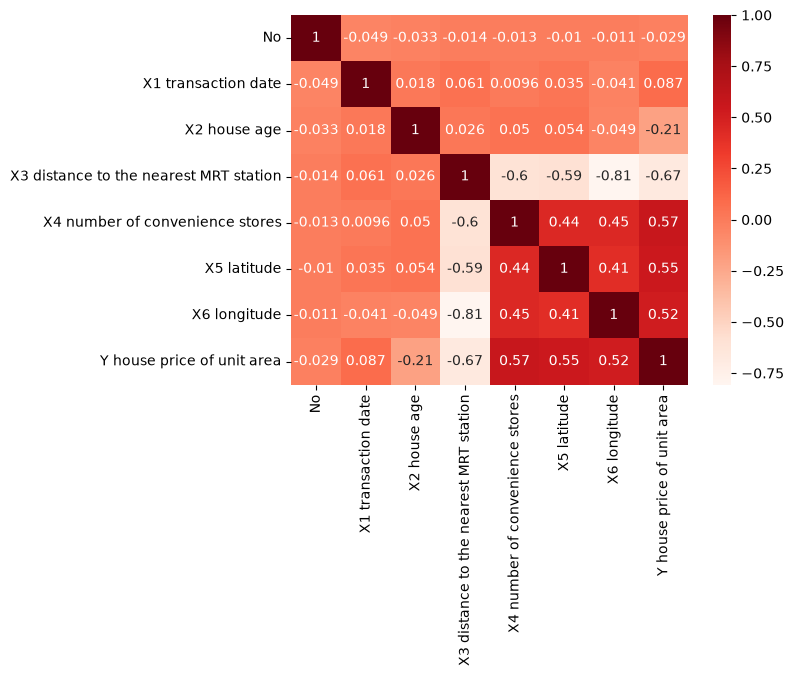

In [ ]:
# Lo vamos a hacer con seaborn 
sns.heatmap(df.corr(), annot=True, cmap='Reds') # El annot sirve para mostrar los valores numericos

Ahora vamos a ver analisis exploratorio con pairplot, aca vamos a poder ver como se distribuyen los datos y como se relacionan las variables mediante graficos

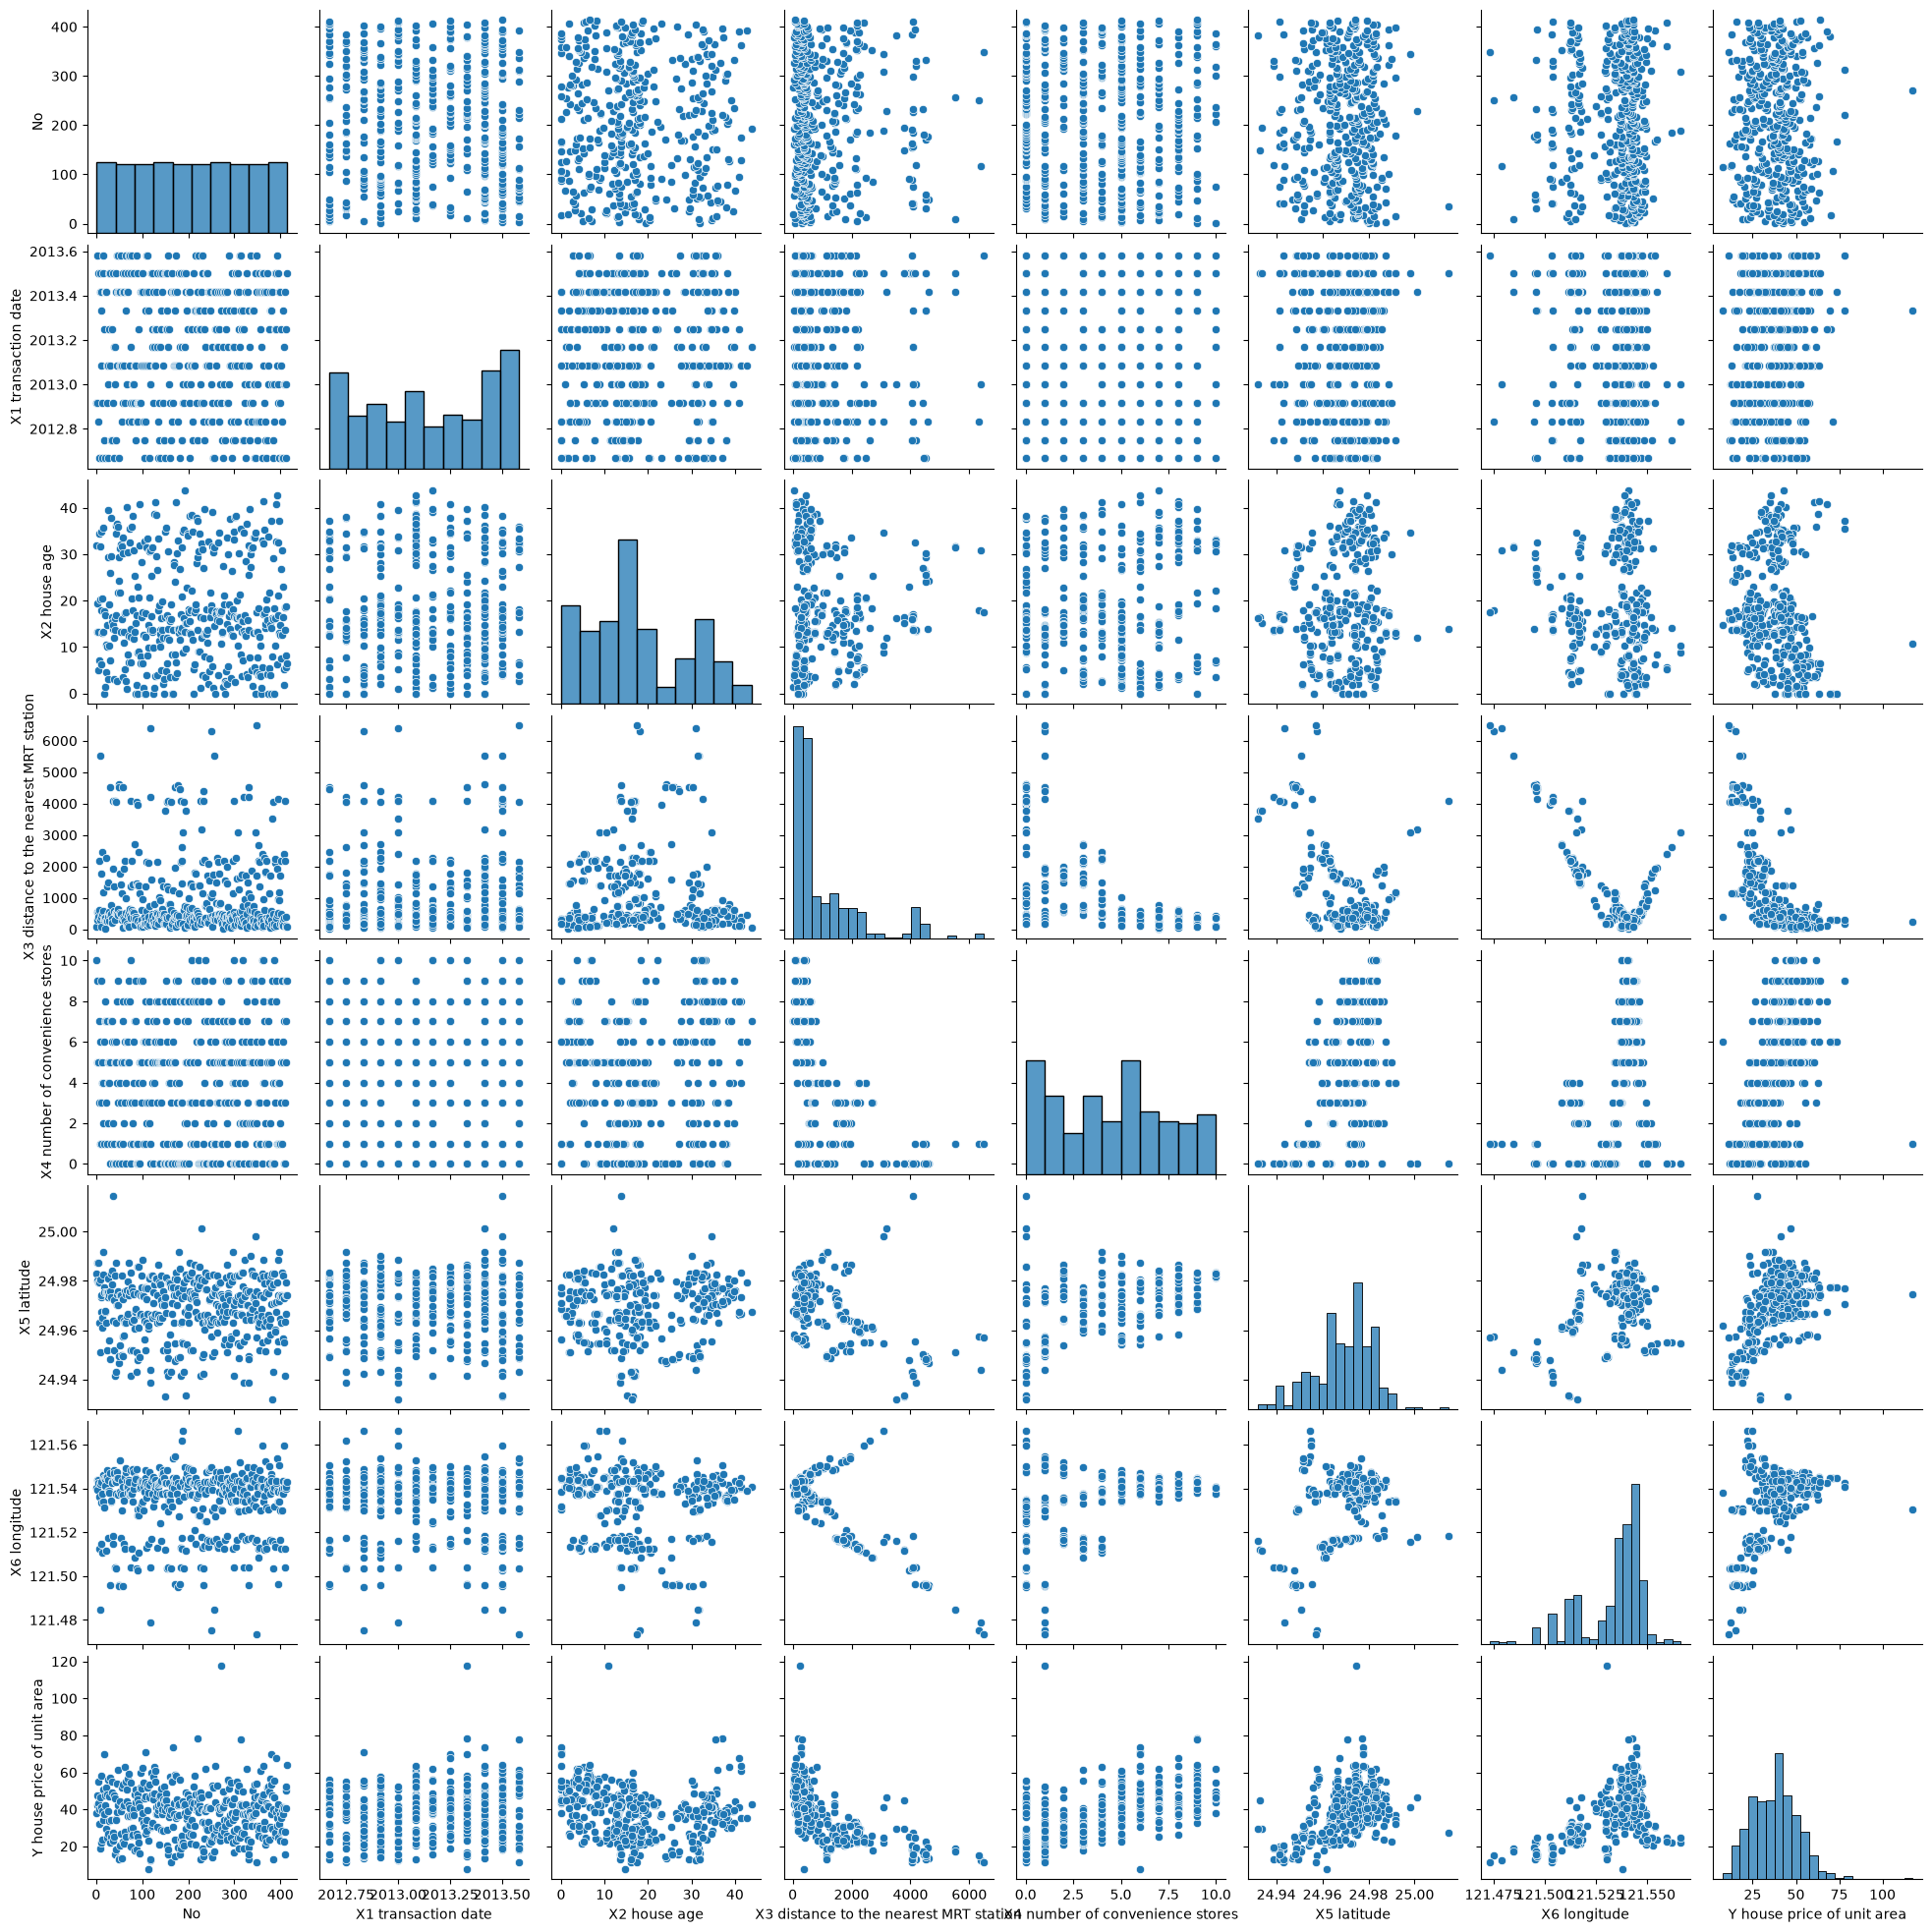

In [ ]:
sns.pairplot(df) # Seaborn toma todas las columnas numéricas del DataFrame y genera automáticamente gráficos que comparan cada variable con las demás.

Ahora vamos a empezar a entrenar el modelo de regresion lineal

In [ ]:
# Definimos las variables predictoras es decir X y la variable objetivo es decir Y

# Tenemos dos formas de hacerlo utilizando la funcion drop o definiendo cada una de esta forma X = df[['Variable_1'., 'Variable_2']], en este caso voy a usar drop
X = df.drop(columns=['No', 'Y house price of unit area'])

y = df['Y house price of unit area']

Ahora vamos a realizar el Train Test Split 

In [ ]:
# Como tenemos un dataframe bastante pequeño utilizamos un 80% para entrenamiento y un 20% para prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [ ]:
print(X_train.shape) # El 80% para entrenamiento
print(X_test.shape) # El 20% para prueba

(331, 6)
(83, 6)


### Definimos el modelo

In [ ]:
modelo = LinearRegression()

In [ ]:
modelo.fit(X_train, y_train);

Ahora evaluamos el modelo
Vamos a utilizar el metodo coef_ para conocer los coeficientes que acompañan a cada variable, es decir cuanto influyen y que aprendio el modelo durante el entrenamiento. 
$$
\hat{Y} = b_0 + b_1X_1 + b_2X_2 + \cdots + b_nX_n
$$
Donde:
* **$\hat{Y}$:** Precio estimado de la vivienda.
* **$b_0$:** Término independiente o intercepto (`model.intercept_`).
* **$b_1, b_2, \ldots$:** Coeficientes aprendidos (`model.coef_`).
* **$X_1, X_2, \ldots$:** Características de las viviendas.


In [ ]:
coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": modelo.coef_
})

print(coeficientes.round(4))

                                 Variable  Coeficiente
0                     X1 transaction date       5.4407
1                            X2 house age      -0.2708
2  X3 distance to the nearest MRT station      -0.0048
3         X4 number of convenience stores       1.0914
4                             X5 latitude     229.0431
5                            X6 longitude     -29.4926


La informacion valiosa que sacamos de aca es:


### 1. ¿Qué representa cada coeficiente?

`model.coef_` devuelve los coeficientes aprendidos durante el entrenamiento. Cada uno indica cuánto cambia el precio estimado cuando una variable aumenta una unidad, **manteniendo las demás constantes**.

| Variable | Coeficiente | Interpretación |
|---|---:|---|
| X1 Fecha de transacción | +5.4407 | Una unidad adicional en la fecha codificada aumenta el precio estimado en 5.44 unidades. |
| X2 Antigüedad | -0.2708 | Cada año adicional reduce el precio estimado en 0.27 unidades. |
| X3 Distancia al MRT | -0.00476 | Cada metro adicional reduce el precio estimado en 0.00476 unidades. |
| X4 Comercios cercanos | +1.0914 | Cada comercio adicional aumenta el precio estimado en 1.09 unidades. |
| X5 Latitud | +229.043 | Cada grado adicional aumenta el precio estimado en 229.04 unidades. |
| X6 Longitud | -29.4926 | Cada grado adicional reduce el precio estimado en 29.49 unidades. |

- **Coeficiente positivo:** al aumentar X, aumenta la predicción.
- **Coeficiente negativo:** al aumentar X, disminuye la predicción.
- Estas relaciones describen el modelo y no necesariamente implican causalidad.

### 2. Ejemplo: distancia al MRT

El coeficiente de X3 es:

$$
b_3=-0.0047586
$$

Si una vivienda está 1.000 metros más lejos de la estación:

$$
1000 \times (-0.0047586)=-4.7586
$$

**Interpretación:** el precio estimado disminuye aproximadamente 4.76 unidades de precio por unidad de superficie, manteniendo las demás variables constantes.

### 3. ¿Por qué la latitud tiene un coeficiente tan grande?

El coeficiente de latitud (X5) es `229.043`, pero esto no significa que sea la variable más importante.

Las variables tienen distintas unidades:
- Distancia: metros.
- Antigüedad: años.
- Latitud: grados geográficos.

Por ejemplo, si la latitud aumenta 0.01 grados:

$$
229.043 \times 0.01 = 2.29043
$$

**Conclusión:** no podemos comparar directamente la magnitud de los coeficientes para determinar qué variable es más importante, porque sus escalas son diferentes.

### 4. ¿Por qué la longitud tiene correlación positiva y coeficiente negativo?

En la matriz de correlación:

- Correlación de X6 con el precio: `+0.52`.
- Coeficiente de X6 en el modelo: `-29.49`.

Esto no es necesariamente un error.

**Diferencia:**

- `df.corr()` mide la relación lineal entre dos variables, sin considerar las demás.
- `model.coef_` indica el cambio estimado en Y cuando aumenta una variable, manteniendo las otras constantes.

Como la latitud, la longitud y la distancia al MRT están relacionadas entre sí, pueden aparecer diferencias entre los signos de las correlaciones y los coeficientes.

**Conclusión general:** los coeficientes permiten interpretar cómo calcula las predicciones nuestro modelo, pero no indican su precisión. Para evaluar el rendimiento debemos utilizar métricas como MAE, RMSE y R².


### Ahora vamos a ver la prediccion de nuestro modelo

In [ ]:
y_pred = modelo.predict(X_test)

Vamos a ver metricas de evaluacion para ver que tan bueno es el modelo, tenemos 3 tipos.
- **Error Absoluto Medio (MAE)** es la media del valor absoluto de los errores:
$$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

- **Error Cuadrático Medio (MSE)** es la media de los errores al cuadrado:
$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

- **Raíz del Error Cuadrático Medio (RMSE)** es la raíz cuadrada de la media de los errores al cuadrado:
$$RMSE = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$

📌 **Comparación de estas métricas:**

* **MAE** es la más fácil de entender, ya que representa el error promedio directo.
* **MSE** es más popular que MAE porque "castiga" los errores más grandes, lo cual suele ser muy útil en el mundo real.
* **RMSE** es aún más popular que MSE porque el resultado se puede interpretar directamente en las mismas unidades de la variable objetivo ("y").
* Todas estas son **funciones de pérdida** (loss functions), ya que nuestro objetivo siempre es minimizarlas.


In [ ]:
MAE= metrics.mean_absolute_error(y_test, y_pred)
MSE=metrics.mean_squared_error(y_test, y_pred)
RMSE= np.sqrt(MSE)

In [ ]:
MAE

5.305355690074272

In [ ]:
MSE

53.50561912450505

In [ ]:
RMSE

np.float64(7.314753524521866)


| $R^2$ | Interpretación orientativa |
| :--- | :--- |
| **1.00** | Predicciones perfectas |
| **0.80** | Buen ajuste relativo al promedio |
| **0.50** | Mejora apreciable sobre el promedio |
| **0.00** | Equivale a predecir siempre el promedio |
| **Negativo** | Peor que predecir siempre el promedio |


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error # Que tambien predice el modelo -> mas cerca de 1 mejor

R2 = r2_score(y_test, y_pred)

print("R²:", R2)

R²: 0.6810580555095769


### Comparación con un modelo básico (Baseline)

Vamos a comparar nuestra regresión lineal con un
modelo que siempre predice el precio promedio
de las viviendas de entrenamiento.

El objetivo es comprobar si nuestro modelo
aprendió patrones útiles de los datos.

In [ ]:
from sklearn.dummy import DummyRegressor

# Crear el modelo básico
modelo_basico = DummyRegressor(strategy="mean")

# Entrenar utilizando los datos de entrenamiento
modelo_basico.fit(X_train, y_train)

# Predecir sobre las mismas viviendas de prueba
y_pred_basico = modelo_basico.predict(X_test)

# Calcular métricas
MAE_basico = metrics.mean_absolute_error(y_test, y_pred_basico)
MSE_basico = metrics.mean_squared_error(y_test, y_pred_basico)
RMSE_basico = np.sqrt(MSE_basico)

# Comparar resultados
comparacion = pd.DataFrame({
    "Métrica": ["MAE", "MSE", "RMSE"],
    "Regresión Lineal": [MAE, MSE, RMSE],
    "Modelo Básico": [MAE_basico, MSE_basico, RMSE_basico]
})

comparacion

,Métrica,Regresión Lineal,Modelo Básico
0,MAE,5.305356,10.916747
1,MSE,53.505619,171.969553
2,RMSE,7.314754,13.113716


In [ ]:
print("R²:", r2_score(y_test, y_pred))

print("MAE entrenamiento:",
      mean_absolute_error(y_train, modelo.predict(X_train)))

print("MAE prueba:",
      mean_absolute_error(y_test, y_pred))

R²: 0.6810580555095769
MAE entrenamiento: 6.339699267157683
MAE prueba: 5.305355690074272


In [ ]:
# Características de la nueva vivienda
nueva_casa = pd.DataFrame([{
    "X1 transaction date": 2013.25,
    "X2 house age": 12,
    "X3 distance to the nearest MRT station": 350,
    "X4 number of convenience stores": 6,
    "X5 latitude": 24.97,
    "X6 longitude": 121.54
}])

# Predecir el precio
precio_predicho = modelo.predict(nueva_casa)

print("Precio estimado:", precio_predicho[0])

Precio estimado: 45.65072677184435


Ahora vamos a hacer comparaciones para ver que tan bien esta lo que hicimos.
Primero agarramos casa con caracteristicas similares y verificamos su precio. Y luego una casa que el modelo aun no vio

In [ ]:
similares = df[
    (df["X3 distance to the nearest MRT station"].between(250, 450)) &
    (df["X2 house age"].between(7, 17)) &
    (df["X4 number of convenience stores"].between(4,8)) 
]

print("Cantidad de viviendas similares:", len(similares))
print("Precio promedio:", similares["Y house price of unit area"].mean())

Cantidad de viviendas similares: 33
Precio promedio: 45.39393939393939


In [ ]:

# Seleccionamos la primera vivienda del conjunto de prueba (X_test).
# iloc permite seleccionar filas por su posición numérica.
# [[0]] selecciona la primera fila y mantiene el formato DataFrame.
casa = X_test.iloc[[0]]

# El modelo predice el precio de la vivienda seleccionada.
# predict() devuelve un array con las predicciones.
# [0] obtiene el primer valor del array (el precio estimado).
precio_predicho = modelo.predict(casa)[0]

# Obtenemos el precio real de la vivienda.
# casa.index devuelve el índice original de la vivienda seleccionada.
# casa.index[0] obtiene el valor de ese índice.
# loc busca en y_test el precio real utilizando ese índice.
precio_real = y_test.loc[casa.index[0]]

# Calculamos la diferencia entre el precio real y el predicho.
# abs() obtiene el valor absoluto, evitando resultados negativos.
# Así conocemos cuánto se equivocó el modelo en esta vivienda.
error = abs(precio_real - precio_predicho)

# Mostramos las características de la vivienda seleccionada.
display(casa)

# Mostramos los resultados para comparar la predicción.
print("Precio real:", precio_real)
print("Precio predicho:", precio_predicho)
print("Error absoluto:", error)


,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
358,2013.167,1.1,193.5845,6,24.96571,121.54089


Precio real: 45.1
Precio predicho: 47.886254217237365
Error absoluto: 2.7862542172373637
